In [4]:
# ============================================================
# SHAP ANALYSIS — XGBoost Baseline vs Enhanced
# Two plots for report:
#   1. Bar plot  — baseline vs enhanced feature importance
#                  side by side (serves RQ1)
#   2. Beeswarm — enhanced XGBoost only, direction + magnitude
#                  (serves interpretability / RQ2)
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import shap
import warnings
warnings.filterwarnings("ignore")

from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error
import os

# ── Paths ──────────────────────────────────────────────────────
# Set BASE to the folder that holds the raw data (see README)
BASE       = "./Data"
OUTPUT_DIR = f"{BASE}/../Processed Data"
PLOT_DIR   = f"{BASE}/../Plots"
os.makedirs(PLOT_DIR, exist_ok=True)

TARGET = "Total_Wildfire_Loss"

# ── Feature sets (must match modeling scripts exactly) ─────────
BASELINE_FEATURES = [
    "County_encoded", "Cal_Year", "Earned_Exp", "Earned_Prem",
    "Avg_Cov_A", "Avg_Cov_C", "Log_Exposure", "Pure_Premium",
    "Loss_Ratio",
]

ENHANCED_FEATURES = [
    "County_encoded", "Cal_Year", "Earned_Exp", "Earned_Prem",
    "Avg_Cov_A", "Avg_Cov_C", "Log_Exposure", "Pure_Premium",
    "Loss_Ratio",
    "Avg_Temperature", "Lag_Avg_Temperature",
    "Avg_Precipitation", "Lag_Avg_Precipitation",
    "Avg_DSCI", "Lag_Avg_DSCI",
    "Burned_Acres", "Lag_Burned_Acres",
]

# ── Load data ──────────────────────────────────────────────────
print("=" * 65)
print("SHAP ANALYSIS — XGBoost Baseline vs Enhanced")
print("=" * 65)

baseline_df = pd.read_csv(f"{OUTPUT_DIR}/master_baseline.csv")
enhanced_df = pd.read_csv(f"{OUTPUT_DIR}/master_enhanced.csv")

# ── Train/test split ───────────────────────────────────────────
# Test sets only — no retraining needed
b_test = baseline_df[baseline_df["Split"] == "test"].copy()
e_test = enhanced_df[enhanced_df["Split"] == "test"].copy()

# ── County target encoding (replicate training encoding) ───────
for df_all, df_test in [(baseline_df, b_test),
                        (enhanced_df,  e_test)]:
    df_train    = df_all[df_all["Split"] == "train"]
    county_mean = df_train.groupby("County")[TARGET].mean()
    df_test["County_encoded"] = (df_test["County"]
                                  .map(county_mean)
                                  .fillna(county_mean.mean()))

y_b_test = b_test[TARGET]
y_e_test = e_test[TARGET]

# ── Load saved XGBoost models ──────────────────────────────────
# Models saved by baseline_modeling.py and enhanced_modeling.py
# No retraining needed
print("\nLoading saved XGBoost models...")

xgb_base = XGBRegressor()
xgb_base.load_model(f"{OUTPUT_DIR}/xgb_baseline_model.json")
base_mae = mean_absolute_error(y_b_test,
    xgb_base.predict(b_test[BASELINE_FEATURES]))
print(f"  Baseline loaded — MAE: ${base_mae:,.0f}  ✅")

xgb_enh = XGBRegressor()
xgb_enh.load_model(f"{OUTPUT_DIR}/xgb_enhanced_model.json")
enh_mae = mean_absolute_error(y_e_test,
    np.clip(xgb_enh.predict(e_test[ENHANCED_FEATURES]), 0, None))
print(f"  Enhanced loaded — MAE: ${enh_mae:,.0f}  ✅")

# ── Compute SHAP values ────────────────────────────────────────
print("\nComputing SHAP values...")

explainer_base = shap.TreeExplainer(xgb_base)
explainer_enh  = shap.TreeExplainer(xgb_enh)

# Use TEST set for SHAP — reflects real prediction behavior
shap_base = explainer_base(b_test[BASELINE_FEATURES])
shap_enh  = explainer_enh(e_test[ENHANCED_FEATURES])

print(f"  Baseline SHAP shape: {shap_base.values.shape}")
print(f"  Enhanced SHAP shape: {shap_enh.values.shape}")

# ── Readable feature name mapping ─────────────────────────────
FEATURE_NAMES = {
    "County_encoded":       "County (target encoded)",
    "Cal_Year":             "Calendar Year",
    "Earned_Exp":           "Earned Exposure",
    "Earned_Prem":          "Earned Premium",
    "Avg_Cov_A":            "Avg Coverage A",
    "Avg_Cov_C":            "Avg Coverage C",
    "Log_Exposure":         "Log Exposure",
    "Pure_Premium":         "Pure Premium",
    "Loss_Ratio":           "Loss Ratio",
    "Avg_Temperature":      "Avg Temperature",
    "Lag_Avg_Temperature":  "Avg Temperature (lag)",
    "Avg_Precipitation":    "Avg Precipitation",
    "Lag_Avg_Precipitation":"Avg Precipitation (lag)",
    "Avg_DSCI":             "Drought Index (DSCI)",
    "Lag_Avg_DSCI":         "Drought Index (lag)",
    "Burned_Acres":         "Burned Acres",
    "Lag_Burned_Acres":     "Burned Acres (lag)",
}

# Apply readable names to shap Explanation objects
shap_base.feature_names = [FEATURE_NAMES[f] for f in BASELINE_FEATURES]
shap_enh.feature_names  = [FEATURE_NAMES[f] for f in ENHANCED_FEATURES]

SHAP ANALYSIS — XGBoost Baseline vs Enhanced

Loading saved XGBoost models...
  Baseline loaded — MAE: $5,852,308  ✅
  Enhanced loaded — MAE: $4,773,544  ✅

Computing SHAP values...
  Baseline SHAP shape: (116, 9)
  Enhanced SHAP shape: (116, 17)



Generating Plot 1: Bar plot — Baseline vs Enhanced...


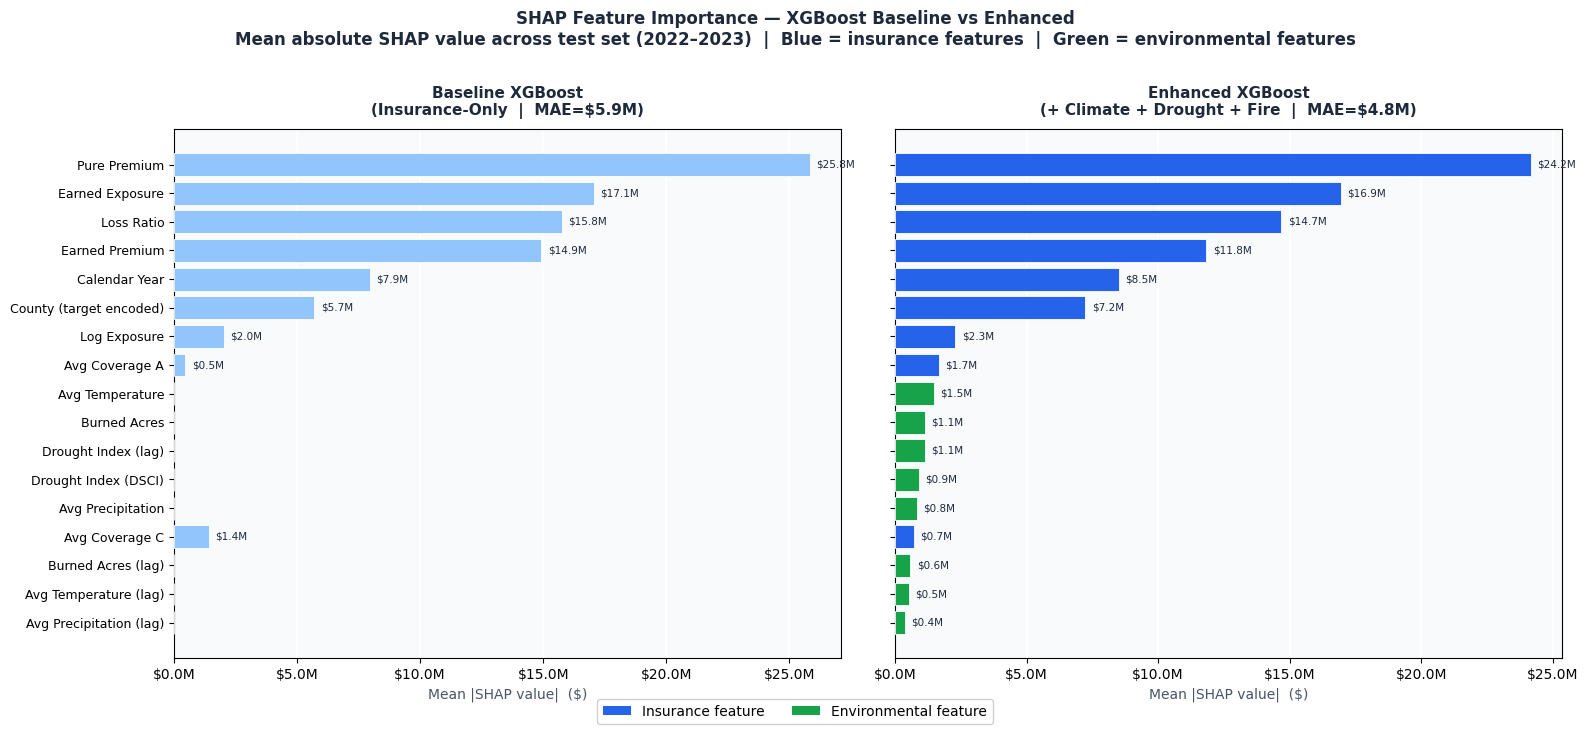

  ✅ shap_bar_baseline_vs_enhanced.png


In [5]:
# ============================================================
# PLOT 1: Bar plot — Baseline vs Enhanced (side by side)
# Mean absolute SHAP value per feature
# ============================================================
print("\nGenerating Plot 1: Bar plot — Baseline vs Enhanced...")

# Compute mean |SHAP| per feature
def mean_abs_shap(shap_obj):
    return pd.Series(
        np.abs(shap_obj.values).mean(axis=0),
        index=shap_obj.feature_names
    ).sort_values(ascending=False)

base_shap_vals = mean_abs_shap(shap_base)
enh_shap_vals  = mean_abs_shap(shap_enh)

# Align — enhanced has more features; baseline gets 0 for env features
all_features = list(enh_shap_vals.index)
base_aligned  = base_shap_vals.reindex(all_features, fill_value=0)
enh_aligned   = enh_shap_vals.reindex(all_features, fill_value=0)

# Sort by enhanced importance
sort_order   = enh_aligned.sort_values().index
base_aligned = base_aligned[sort_order]
enh_aligned  = enh_aligned[sort_order]

# Colors — insurance features vs environmental features
INS_FEATURES_READABLE = [FEATURE_NAMES[f] for f in BASELINE_FEATURES]
bar_colors_base = ["#93C5FD" if f in INS_FEATURES_READABLE
                   else "#BBF7D0" for f in sort_order]
bar_colors_enh  = ["#2563EB" if f in INS_FEATURES_READABLE
                   else "#16A34A" for f in sort_order]

fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharey=True)
fig.patch.set_facecolor("white")

for ax, vals, colors, title, mae in [
        (axes[0], base_aligned, bar_colors_base,
         f"Baseline XGBoost\n(Insurance-Only  |  MAE=${base_mae/1e6:.1f}M)",
         base_mae),
        (axes[1], enh_aligned,  bar_colors_enh,
         f"Enhanced XGBoost\n(+ Climate + Drought + Fire  |  MAE=${enh_mae/1e6:.1f}M)",
         enh_mae)]:

    bars = ax.barh(range(len(vals)), vals.values,
                   color=colors, edgecolor="white",
                   linewidth=0.6, zorder=3)
    ax.set_yticks(range(len(vals)))
    ax.set_yticklabels(vals.index, fontsize=9)
    ax.set_xlabel("Mean |SHAP value|  ($)",
                  fontsize=10, color="#475569")
    ax.set_title(title, fontsize=11,
                 fontweight="bold", color="#1E293B", pad=10)
    ax.set_facecolor("#F8FAFC")
    ax.grid(axis="x", color="white", linewidth=1.5, zorder=0)
    ax.xaxis.set_major_formatter(
        plt.FuncFormatter(lambda x, _: f"${x/1e6:.1f}M"))

    # Value labels
    for bar, val in zip(bars, vals.values):
        if val > 0:
            ax.text(bar.get_width() + vals.values.max() * 0.01,
                    bar.get_y() + bar.get_height() / 2,
                    f"${val/1e6:.1f}M", va="center",
                    fontsize=7.5, color="#1E293B")

# Shared legend
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor="#2563EB", label="Insurance feature"),
    Patch(facecolor="#16A34A", label="Environmental feature"),
]
fig.legend(handles=legend_elements, loc="lower center",
           ncol=2, fontsize=10, framealpha=0.9,
           bbox_to_anchor=(0.5, -0.02))

fig.suptitle(
    "SHAP Feature Importance — XGBoost Baseline vs Enhanced\n"
    "Mean absolute SHAP value across test set (2022–2023)  |  "
    "Blue = insurance features  |  Green = environmental features",
    fontsize=12, fontweight="bold", color="#1E293B", y=1.01)

plt.tight_layout()
plt.savefig(f"{PLOT_DIR}/shap_bar_baseline_vs_enhanced.png",
            dpi=150, bbox_inches="tight", facecolor="white")
plt.show()
print("  ✅ shap_bar_baseline_vs_enhanced.png")



Generating Plot 2: Beeswarm — Enhanced XGBoost...


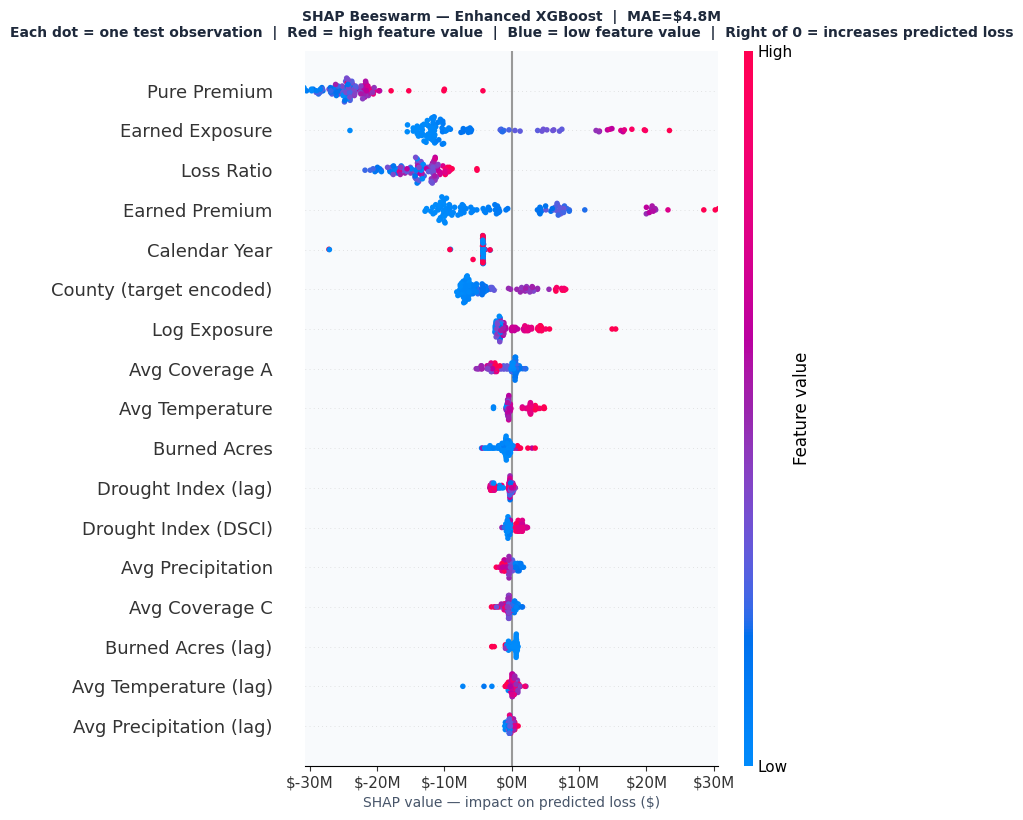

  ✅ shap_beeswarm_enhanced.png


In [7]:
# ============================================================
# PLOT 2: Beeswarm — Enhanced XGBoost only
# Shows direction + magnitude + distribution
# ============================================================
print("\nGenerating Plot 2: Beeswarm — Enhanced XGBoost...")

fig, ax = plt.subplots(figsize=(11, 7))
fig.patch.set_facecolor("white")
ax.set_facecolor("#F8FAFC")

shap.plots.beeswarm(shap_enh,
                    max_display=17,
                    show=False,
                    color_bar=True)

# Clip x-axis to 95th percentile of absolute SHAP values
# Removes extreme outliers that compress the majority of features
shap_abs_95 = np.percentile(np.abs(shap_enh.values), 95)
plt.xlim(-shap_abs_95 * 1.3, shap_abs_95 * 1.3)

# Update x-axis tick labels to $M format
ax = plt.gca()
ax.xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"${x/1e6:.0f}M"))
ax.set_xlabel("SHAP value — impact on predicted loss ($)",
              fontsize=10, color="#475569")

plt.title(
    f"SHAP Beeswarm — Enhanced XGBoost  |  MAE=${enh_mae/1e6:.1f}M\n"
    "Each dot = one test observation  |  "
    "Red = high feature value  |  Blue = low feature value  |  "
    "Right of 0 = increases predicted loss",
    fontsize=10, fontweight="bold", color="#1E293B", pad=10)

plt.tight_layout()
plt.savefig(f"{PLOT_DIR}/shap_beeswarm_enhanced.png",
            dpi=150, bbox_inches="tight", facecolor="white")
plt.show()
print("  ✅ shap_beeswarm_enhanced.png")